# Gradient-based MCMC: Langevin, HMC and NUTS

ELG 5218 — interactive companion to the slides.

**How to use this notebook**
- Run all cells from the top (*Run → Run All*).
- Cells marked **🔒 hidden** contain plotting or helper code. Their code is collapsed: click the cell's left bar (Jupyter/VS Code) or *Show code* (Colab) to reveal and edit it.
- Short **visible** cells contain the algorithms and the parameters you are invited to change. Sliders re-run the experiments.

Requires `numpy`, `matplotlib`, `ipywidgets` (all available in Colab).

**Section 0** shows how to generate samples directly from a normal distribution, a correlated multivariate normal, and a multimodal mixture; sections 1–16 cover MCMC; section 17 returns to the mixture.

**Running example.** Most experiments use a 2D Gaussian posterior with strong correlation $\rho$ (a narrow, tilted valley), and a 1D posterior with two peaks.

In [ ]:
#@title 🔒 hidden: setup, targets, and helper functions
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown, Checkbox
%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "animation.embed_limit": 60})
BLUE, RED, TEAL, ORANGE, GRAY, PURPLE, GREEN = "#378ADD", "#C0392B", "#1D9E75", "#D85A30", "#888780", "#7F77DD", "#2E7D32"
trapz = getattr(np, "trapezoid", None) or np.trapz

# ---------- 2D valley: N(0, [[1, rho], [rho, 1]]) ----------
class Valley:
    def __init__(self, rho=0.9):
        self.rho = rho
        self.S = np.array([[1.0, rho], [rho, 1.0]])
        self.P = np.linalg.inv(self.S)
    def U(self, q):  return 0.5 * q @ self.P @ q          # U = -log pi (up to a constant)
    def gU(self, q): return self.P @ q                    # gradient of U
    def contours(self, ax, radii=(1, 2, 3)):
        t = np.linspace(0, 2 * np.pi, 200); L = np.linalg.cholesky(self.S)
        for r in radii:
            z = r * np.vstack([np.cos(t), np.sin(t)]); xy = L @ z
            ax.plot(xy[0], xy[1], color=GRAY, lw=0.8, alpha=0.7)
        ax.set_aspect("equal"); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2)
        ax.set_xlabel(r"$\theta_1$"); ax.set_ylabel(r"$\theta_2$")

# ---------- 1D posterior with two peaks ----------
W1, M1, S1, M2, S2 = 0.6, -1.0, 0.6, 1.3, 0.8
def npdf(t, m, s): return np.exp(-0.5 * ((t - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
def pi1(t):  return W1 * npdf(t, M1, S1) + (1 - W1) * npdf(t, M2, S2)
def U1(t):   return -np.log(pi1(t) + 1e-300)
def gU1(t):
    d = W1 * npdf(t, M1, S1) * (-(t - M1) / S1**2) + (1 - W1) * npdf(t, M2, S2) * (-(t - M2) / S2**2)
    return -d / (pi1(t) + 1e-300)
G1 = np.linspace(-4, 5, 600); Z1 = trapz(pi1(G1), G1)
TRUE_MEAN1 = trapz(G1 * pi1(G1), G1) / Z1
TRUE_VAR1 = trapz((G1 - TRUE_MEAN1) ** 2 * pi1(G1), G1) / Z1

def ess(x, max_lag=2000):
    """Effective sample size (Geyer's initial positive sequence). Can exceed N for anti-correlated chains."""
    x = np.asarray(x, float) - np.mean(x); n = len(x); v = x.var()
    if v == 0: return 1.0
    rho = lambda k: 1.0 if k == 0 else np.dot(x[:-k], x[k:]) / (n * v)
    tau, m = -1.0, 0
    while 2 * m + 1 < min(max_lag, n - 1):
        pair = rho(2 * m) + rho(2 * m + 1)
        if pair < 0: break
        tau += 2 * pair; m += 1
    # cap as in Stan (ESS <= N log10 N): strongly anti-correlated chains can otherwise give absurd values
    return min(n / max(tau, 1e-3), n * np.log10(n))
print("setup done")

setup done


## 0. Before MCMC: generating samples directly

When a distribution is simple and fully known (including its normalizing constant), we can generate **independent** samples directly, without any Markov chain. MCMC is needed only when this is impossible, as for most posteriors. This section shows the three building blocks.

### 0.1 One normal distribution
Computers produce **uniform** random numbers $u\sim\mathrm{Unif}(0,1)$. A standard normal $z\sim\mathcal N(0,1)$ can be made from two uniforms with the **Box–Muller** transform:
$$
z=\sqrt{-2\log u_1}\,\cos(2\pi u_2).
$$
Any other normal is a shifted and stretched standard normal:
$$
x=\mu+\sigma z\ \sim\ \mathcal N(\mu,\sigma^2).
$$
(`rng.normal()` in NumPy does exactly this kind of transformation for you.)

In [ ]:
def std_normal_box_muller(n, rng):
    """n standard normal numbers from 2n uniform numbers (Box-Muller)."""
    u1, u2 = rng.uniform(size=n), rng.uniform(size=n)
    return np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)

def sample_normal(mu, sigma, n, rng):
    return mu + sigma * std_normal_box_muller(n, rng)      # shift and stretch

In [ ]:
#@title 🔒 hidden: plot for section 0.1
def normal1d_demo(mu=2.0, sigma=0.7, n=5000, seed=0):
    rng = np.random.default_rng(seed)
    u1, u2 = rng.uniform(size=n), rng.uniform(size=n)
    z = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2); x = mu + sigma * z
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    ax[0].hist(u1, bins=30, density=True, color=GRAY, alpha=0.6); ax[0].set_title("uniform numbers $u_1$ (input)")
    g = np.linspace(-4, 4, 200)
    ax[1].hist(z, bins=50, density=True, color=BLUE, alpha=0.5); ax[1].plot(g, npdf(g, 0, 1), "k")
    ax[1].set_title("Box-Muller output $z$ vs $\\mathcal{N}(0,1)$")
    g2 = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 200)
    ax[2].hist(x, bins=50, density=True, color=TEAL, alpha=0.5); ax[2].plot(g2, npdf(g2, mu, sigma), "k")
    ax[2].set_title(f"$x=\\mu+\\sigma z$: mean {x.mean():.2f}, sd {x.std():.2f}")
    plt.tight_layout(); plt.show()
interact(normal1d_demo, mu=FloatSlider(value=2.0, min=-3, max=3, step=0.1, continuous_update=False),
         sigma=FloatSlider(value=0.7, min=0.1, max=3, step=0.1, continuous_update=False),
         n=IntSlider(value=5000, min=100, max=50000, step=100, continuous_update=False),
         seed=IntSlider(value=0, min=0, max=30, continuous_update=False));

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='mu', max=3.0, min=-3.0), Fl…

**What you see.** Left: flat histogram of uniform numbers. Middle: after Box–Muller they follow the bell curve of $\mathcal N(0,1)$. Right: shifting by $\mu$ and stretching by $\sigma$ gives $\mathcal N(\mu,\sigma^2)$; the printed sample mean and SD are close to the chosen $\mu$ and $\sigma$.

### 0.2 A correlated multivariate normal $\mathcal N(\mu,\Sigma)$
Draw a vector $z$ of **independent** standard normals and transform it with the **Cholesky factor** $L$ of the covariance ($\Sigma=LL^\top$, $L$ lower triangular):
$$
\theta=\mu+Lz .
$$
Why it works: $\mathrm{Cov}(\theta)=L\,\mathrm{Cov}(z)\,L^\top=LIL^\top=\Sigma$. In 2D with standard deviations $\sigma_1,\sigma_2$ and correlation $\rho$:
$$
\Sigma=\begin{pmatrix}\sigma_1^2&\rho\sigma_1\sigma_2\\ \rho\sigma_1\sigma_2&\sigma_2^2\end{pmatrix},\qquad
L=\begin{pmatrix}\sigma_1&0\\ \rho\sigma_2&\sigma_2\sqrt{1-\rho^2}\end{pmatrix}.
$$

In [ ]:
def make_cov(s1, s2, rho):
    return np.array([[s1**2, rho * s1 * s2], [rho * s1 * s2, s2**2]])

def sample_mvn(mu, Sigma, n, rng):
    L = np.linalg.cholesky(Sigma)                  # Sigma = L L^T
    z = rng.normal(size=(n, len(mu)))              # independent standard normals
    return np.asarray(mu) + z @ L.T                # theta = mu + L z  (one row per sample)

In [ ]:
#@title 🔒 hidden: plot for section 0.2
def ellipse(ax, mu, Sigma, color, radii=(1, 2), **kw):
    t = np.linspace(0, 2 * np.pi, 200); L = np.linalg.cholesky(Sigma)
    for r in radii:
        xy = np.asarray(mu)[:, None] + L @ (r * np.vstack([np.cos(t), np.sin(t)]))
        ax.plot(xy[0], xy[1], color=color, **kw)
def mvn_demo(mu1=1.0, mu2=-0.5, s1=1.0, s2=0.6, rho=0.8, n=2000, seed=0):
    rng = np.random.default_rng(seed); mu = np.array([mu1, mu2]); Sig = make_cov(s1, s2, rho)
    z = rng.normal(size=(n, 2)); L = np.linalg.cholesky(Sig); th = mu + z @ L.T
    fig, ax = plt.subplots(1, 2, figsize=(11, 5))
    ax[0].plot(z[:, 0], z[:, 1], ".", ms=2, color=GRAY, alpha=0.6); ellipse(ax[0], [0, 0], np.eye(2), "k", lw=1)
    ax[0].set_title("step 1: independent standard normals $z$"); ax[0].set_aspect("equal"); ax[0].set_xlim(-4, 4); ax[0].set_ylim(-4, 4)
    ax[1].plot(th[:, 0], th[:, 1], ".", ms=2, color=BLUE, alpha=0.6); ellipse(ax[1], mu, Sig, "k", lw=1)
    ax[1].set_aspect("equal"); ax[1].set_xlim(mu1 - 4, mu1 + 4); ax[1].set_ylim(mu2 - 4, mu2 + 4)
    C = np.cov(th.T)
    ax[1].set_title(f"step 2: $\\theta=\\mu+Lz$\nsample corr {C[0,1] / np.sqrt(C[0,0] * C[1,1]):.2f} (target {rho:.2f}), "
                    f"sds {np.sqrt(C[0,0]):.2f}, {np.sqrt(C[1,1]):.2f}", fontsize=10)
    for a in ax: a.set_xlabel(r"$\theta_1$"); a.set_ylabel(r"$\theta_2$")
    plt.tight_layout(); plt.show()
interact(mvn_demo, mu1=FloatSlider(value=1.0, min=-2, max=2, step=0.1, continuous_update=False),
         mu2=FloatSlider(value=-0.5, min=-2, max=2, step=0.1, continuous_update=False),
         s1=FloatSlider(value=1.0, min=0.2, max=2, step=0.1, continuous_update=False),
         s2=FloatSlider(value=0.6, min=0.2, max=2, step=0.1, continuous_update=False),
         rho=FloatSlider(value=0.8, min=-0.99, max=0.99, step=0.01, continuous_update=False),
         n=IntSlider(value=2000, min=100, max=20000, step=100, continuous_update=False),
         seed=IntSlider(value=0, min=0, max=30, continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='mu1', max=2.0, min=-2.0), F…

**What you see.** Left: the independent standard normals form a round cloud (black circles: radius 1 and 2). Right: the same points after $\theta=\mu+Lz$. The circle is stretched, rotated and shifted into an ellipse with the chosen means, standard deviations and correlation; the printed sample correlation and SDs match the targets. Set $\rho$ near $\pm1$ to get a narrow, tilted valley like the one used throughout this notebook.

### 0.3 A multimodal distribution: a mixture of correlated normals
A mixture with weights $w_1,\dots,w_K$ (summing to 1):
$$
p(\theta)=\sum_{k=1}^K w_k\,\mathcal N(\theta\mid\mu_k,\Sigma_k).
$$
It has several peaks (modes), each with its own correlation. Sampling uses two steps (**ancestral sampling**):
1. pick a component $k$ with probabilities $w_1,\dots,w_K$;
2. draw $\theta\sim\mathcal N(\mu_k,\Sigma_k)$ with the Cholesky method above.

Each sample is independent of the others, so modes are never a problem here.

In [ ]:
def sample_mixture(weights, mus, Sigmas, n, rng):
    k = rng.choice(len(weights), size=n, p=weights)        # 1. which component? (random)
    out = np.empty((n, len(mus[0])))
    for j in range(len(weights)):
        idx = (k == j)
        out[idx] = sample_mvn(mus[j], Sigmas[j], idx.sum(), rng)   # 2. sample from that normal
    return out, k

def mixture_logpdf(theta, weights, mus, Sigmas):
    """log p(theta) for a mixture of normals (theta: array of shape (..., d))."""
    theta = np.atleast_2d(theta); terms = []
    for w, m, S in zip(weights, mus, Sigmas):
        d = theta - m; P = np.linalg.inv(S)
        q = np.einsum("ni,ij,nj->n", d, P, d)
        terms.append(np.log(w) - 0.5 * q - 0.5 * np.log(np.linalg.det(2 * np.pi * S)))
    terms = np.array(terms); mx = terms.max(0)
    return mx + np.log(np.exp(terms - mx).sum(0))

In [ ]:
#@title 🔒 hidden: plot for section 0.3
def mixture_setup(sep=3.0, w1=0.5, w2=0.3, rho1=0.8, rho2=-0.7, rho3=0.0):
    w3 = max(0.0, 1 - w1 - w2); W = np.array([w1, w2, w3]); W = W / W.sum()
    mus = [np.array([-sep, -sep / 2]), np.array([sep, -sep / 2]), np.array([0.0, sep])]
    Sigmas = [make_cov(1.0, 0.7, rho1), make_cov(0.8, 1.0, rho2), make_cov(0.7, 0.7, rho3)]
    return W, mus, Sigmas
def mixture_demo(sep=3.0, w1=0.5, w2=0.3, rho1=0.8, rho2=-0.7, rho3=0.0, n=3000, seed=0):
    W, mus, Sigmas = mixture_setup(sep, w1, w2, rho1, rho2, rho3); rng = np.random.default_rng(seed)
    th, k = sample_mixture(W, mus, Sigmas, n, rng)
    lim = sep + 3.5; gx = np.linspace(-lim, lim, 160); GX, GY = np.meshgrid(gx, gx)
    dens = np.exp(mixture_logpdf(np.column_stack([GX.ravel(), GY.ravel()]), W, mus, Sigmas)).reshape(GX.shape)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].contour(GX, GY, dens, levels=8, colors=GRAY, linewidths=0.7)
    for j, c in enumerate([BLUE, ORANGE, TEAL]):
        ax[0].plot(th[k == j, 0], th[k == j, 1], ".", ms=2, color=c, alpha=0.6, label=f"component {j + 1}: w = {W[j]:.2f}")
    ax[0].set_aspect("equal"); ax[0].legend(frameon=False, fontsize=8, markerscale=4); ax[0].set_title("samples coloured by the chosen component")
    ax[0].set_xlabel(r"$\theta_1$"); ax[0].set_ylabel(r"$\theta_2$")
    marg = sum(w * npdf(gx, m[0], np.sqrt(S[0, 0])) for w, m, S in zip(W, mus, Sigmas))
    ax[1].hist(th[:, 0], bins=60, density=True, color=PURPLE, alpha=0.5, label="samples")
    ax[1].plot(gx, marg, "k", label="exact marginal"); ax[1].legend(frameon=False)
    ax[1].set_xlabel(r"$\theta_1$"); ax[1].set_title(r"marginal of $\theta_1$")
    print("fraction of samples per component:", np.round(np.bincount(k, minlength=3) / n, 3), " target:", np.round(W, 3))
    plt.tight_layout(); plt.show()
interact(mixture_demo, sep=FloatSlider(value=3.0, min=0.5, max=6, step=0.1, continuous_update=False),
         w1=FloatSlider(value=0.5, min=0.05, max=0.9, step=0.05, continuous_update=False),
         w2=FloatSlider(value=0.3, min=0.05, max=0.9, step=0.05, continuous_update=False),
         rho1=FloatSlider(value=0.8, min=-0.95, max=0.95, step=0.05, continuous_update=False),
         rho2=FloatSlider(value=-0.7, min=-0.95, max=0.95, step=0.05, continuous_update=False),
         rho3=FloatSlider(value=0.0, min=-0.95, max=0.95, step=0.05, continuous_update=False),
         n=IntSlider(value=3000, min=200, max=20000, step=200, continuous_update=False),
         seed=IntSlider(value=0, min=0, max=30, continuous_update=False));

interactive(children=(FloatSlider(value=3.0, continuous_update=False, description='sep', max=6.0, min=0.5), Fl…

**What you see.** Left: three clouds, one per component, each tilted according to its own correlation (grey lines: contours of the mixture density). Colours show which component was picked in step 1; the printed fractions match the weights. Right: the histogram of $\theta_1$ matches the exact marginal, which can have several bumps. Move the separation: however far apart the modes are, direct sampling fills all of them correctly, because every sample starts afresh.

**Why not always do this?** Direct sampling needs the distribution in a known, simple form. A posterior $p(\theta\mid x)\propto p(x\mid\theta)p(\theta)$ is usually known only up to a constant and has no such recipe. That is why we need MCMC (section 1 onward). Section 17 returns to this mixture and asks how MCMC copes with several modes.

## 1. What is "wrong" with random-walk MH?

**RWM = random-walk Metropolis** (random-walk Metropolis–Hastings): propose $\theta^\ast=\theta+\epsilon$ with $\epsilon\sim\mathcal N(0,\sigma^2 I)$, accept with probability $\min(1,\pi(\theta^\ast)/\pi(\theta))$. It is the sampler from the previous lecture.

- Proposals are **blind**: $\theta^\ast=\theta+\epsilon$ ignores the shape of $\pi$.
- The chain moves by small, undirected steps that often undo each other: after $n$ steps it has typically moved only $\propto\sqrt n$ step lengths.
- In a **narrow, tilted valley** (correlated parameters) the step must fit the narrow direction, so progress along the long direction is slow.
- In **high dimension** the step must shrink like $d^{-1/2}$.

**Try:** increase the correlation $\rho$ to 0.98; then try a larger step $\sigma$ and watch the acceptance rate collapse.

In [ ]:
def rwm(target, n_iter, sigma, q0=(-1.6, -1.4), seed=0):
    """Random-walk Metropolis. Returns the chain and the acceptance rate."""
    rng = np.random.default_rng(seed); q = np.array(q0, float); chain, acc = [q.copy()], 0
    for _ in range(n_iter):
        prop = q + sigma * rng.normal(size=2)                  # blind proposal
        if np.log(rng.uniform()) < target.U(q) - target.U(prop):   # MH ratio pi(prop)/pi(q)
            q = prop; acc += 1
        chain.append(q.copy())
    return np.array(chain), acc / n_iter

In [ ]:
#@title 🔒 hidden: plot for section 1
def rwm_demo(rho=0.9, sigma=0.35, n_iter=200, seed=0):
    T = Valley(rho); ch, acc = rwm(T, n_iter, sigma, seed=seed)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
    T.contours(ax[0]); ax[0].plot(ch[:, 0], ch[:, 1], ".-", color=RED, ms=3, lw=0.8)
    ax[0].set_title(f"RWM, {n_iter} iterations")
    ax[1].plot(ch[:, 0], color=RED, lw=0.8); ax[1].set_xlabel("iteration"); ax[1].set_ylabel(r"$\theta_1$")
    ax[1].set_title(f"trace: acceptance {acc:.2f}, ESS({chr(952)}1) = {ess(ch[:,0]):.0f} of {n_iter}")
    plt.tight_layout(); plt.show()
interact(rwm_demo, rho=FloatSlider(value=0.9, min=0, max=0.99, step=0.01, continuous_update=False),
         sigma=FloatSlider(value=0.35, min=0.05, max=2.0, step=0.05, continuous_update=False),
         n_iter=IntSlider(value=200, min=50, max=3000, step=50, continuous_update=False),
         seed=IntSlider(value=0, min=0, max=30, continuous_update=False));

interactive(children=(FloatSlider(value=0.9, continuous_update=False, description='rho', max=0.99, step=0.01),…

**What you see.** Left: the chain's path inside the valley (grey ellipses = contours of $\pi$). With $\rho=0.9$ and $\sigma=0.35$ the path is a tangle of short steps that covers only part of the valley. Right: the trace of $\theta_1$ wanders slowly; consecutive values are strongly correlated, so the ESS is a small fraction of the iterations.

## 2. The landscape view: $U(\theta)=-\log\tilde\pi(\theta)$

- High probability $\Leftrightarrow$ **low** $U$ (a valley).
- $-\nabla U(\theta)=\nabla\log\tilde\pi(\theta)$ points **downhill**, toward higher probability.
- Only $\nabla\log\tilde\pi$ is needed: the evidence is a constant and disappears from the gradient.
- For a posterior, $\nabla\log\tilde\pi(\theta)=\nabla\log p(x\mid\theta)+\nabla\log p(\theta)$.

**Try:** move $\theta$ and watch the arrow $-\nabla U$: it always points toward the nearer valley floor.

In [ ]:
#@title 🔒 hidden: plot for section 2
def landscape_demo(theta=-2.2):
    fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
    ax[0].plot(G1, pi1(G1), color="black"); ax[0].axvline(theta, color=ORANGE, ls=":")
    ax[0].set_title(r"posterior $\tilde\pi(\theta)$ (peaks)")
    ax[1].plot(G1, np.minimum(U1(G1), 8), color=GRAY, lw=2); ax[1].set_ylim(0, 8)
    u, g = U1(theta), gU1(theta)
    ax[1].plot(theta, u, "o", color=ORANGE, ms=9)
    ax[1].annotate("", xy=(theta - 0.35 * np.sign(g) * min(abs(g), 3) / 3 * 2, u), xytext=(theta, u),
                   arrowprops=dict(arrowstyle="->", color=ORANGE, lw=2.5))
    ax[1].set_title(rf"landscape $U(\theta)=-\log\tilde\pi(\theta)$;  at $\theta$={theta:.2f}: $-\nabla U$ = {-g:.2f}")
    ax[1].set_xlabel(r"$\theta$"); plt.tight_layout(); plt.show()
interact(landscape_demo, theta=FloatSlider(value=-2.2, min=-3.5, max=4.5, step=0.05, continuous_update=False));

interactive(children=(FloatSlider(value=-2.2, continuous_update=False, description='theta', max=4.5, min=-3.5,…

**What you see.** Top: the posterior with two peaks. Bottom: the same function turned upside down and on a log scale; the peaks became valleys. The orange arrow, $-\nabla U$, always points toward the bottom of the nearest valley, i.e. toward higher probability.

## 3. Why not simply follow the gradient?

$\theta\leftarrow\theta-\eta\nabla U(\theta)$ is **optimization**: it ends at the peak (the MAP estimate) and stays there. All "samples" collapse onto one point and the **uncertainty is lost**. A sampler must visit every region *in proportion to its probability*.

What is needed: **gradient** (aim) + **randomness** (spread) + a **correction** (exact balance).

**Try:** any step size $\eta$ (small enough to be stable) ends at the same point. The histogram on the right should match the black curve if we were sampling; it does not.

In [ ]:
#@title 🔒 hidden: plot for section 3
def gd_demo(eta=0.03, steps=80, start1=-2.2, start2=-1.2):
    T = Valley(0.9); q = np.array([start1, start2]); path = [q.copy()]
    for _ in range(steps): q = q - eta * T.gU(q); path.append(q.copy())
    path = np.array(path)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
    T.contours(ax[0]); ax[0].plot(path[:, 0], path[:, 1], ".-", color=ORANGE, ms=3); ax[0].plot(0, 0, "k*", ms=12)
    ax[0].set_title("gradient steps only")
    ax[1].hist(path[steps // 2:, 0], bins=30, density=True, color=ORANGE, alpha=0.6, label="'samples' (2nd half)")
    x = np.linspace(-3.5, 3.5, 200); ax[1].plot(x, npdf(x, 0, 1), "k", label=r"true marginal of $\theta_1$")
    ax[1].legend(frameon=False); ax[1].set_xlabel(r"$\theta_1$"); ax[1].set_title("the spread is lost")
    plt.tight_layout(); plt.show()
interact(gd_demo, eta=FloatSlider(value=0.03, min=0.005, max=0.18, step=0.005, continuous_update=False),
         steps=IntSlider(value=80, min=5, max=400, continuous_update=False),
         start1=FloatSlider(value=-2.2, min=-3, max=3, step=0.1, continuous_update=False),
         start2=FloatSlider(value=-1.2, min=-3, max=3, step=0.1, continuous_update=False));

interactive(children=(FloatSlider(value=0.03, continuous_update=False, description='eta', max=0.18, min=0.005,…

**What you see.** Left: the gradient steps run straight to the centre (the most probable point) and stay there. Right: the "samples" form a spike instead of the black bell curve: optimization finds the peak but throws away the uncertainty.

## 4. Langevin dynamics: drift plus noise

**Physics:** a particle in thick syrup on the landscape $U$. It slides downhill (**drift**) and is jostled by random kicks (**noise**). Friction removes its momentum immediately.
$$
d\theta_t=-\tfrac12\nabla U(\theta_t)\,dt+dW_t .
$$
- Drift pushes probability **toward** the valleys; noise spreads it **out**. They balance exactly when the density is $\pi\propto e^{-U}$.
- Discretize with time step $\Delta t$: $\;\tilde\theta=\theta_k-\tfrac{\Delta t}{2}\nabla U(\theta_k)+\sqrt{\Delta t}\,Z_k,\ Z_k\sim\mathcal N(0,I)$.
- Accept every step: **ULA** (unadjusted, slightly biased). Add an MH accept/reject: **MALA** (exact).

**Animation:** 1000 particles all start at $\theta=3.5$. Each frame applies one ULA step to every particle. Watch the histogram flow into the shape of $\pi$: drift and noise reach a balance.

In [ ]:
# Change these and re-run the cell
N_PARTICLES, DT, N_FRAMES, START = 1000, 0.06, 800, 3.5

In [ ]:
#@title 🔒 hidden: animation for section 4
def langevin_particles(n=N_PARTICLES, dt=DT, frames=N_FRAMES, start=START, seed=0):
    rng = np.random.default_rng(seed); x = np.full(n, float(start)); hist = [x.copy()]
    for _ in range(frames):
        for __ in range(3):
            x = x - 0.5 * dt * gU1(x) + np.sqrt(dt) * rng.normal(size=n)
        hist.append(x.copy())
    fig, ax = plt.subplots(figsize=(8, 3.6), dpi=72); bins = np.linspace(-4, 5, 60)
    def frame(k):
        ax.clear(); ax.hist(hist[k], bins=bins, density=True, color=TEAL, alpha=0.6)
        ax.plot(G1, pi1(G1) / Z1, "k", lw=1.5); ax.set_ylim(0, 1.0); ax.set_xlim(-4, 5)
        ax.set_title(f"Langevin particles, time = {3 * k * dt:.2f}"); ax.set_xlabel(r"$\theta$")
    anim = animation.FuncAnimation(fig, frame, frames=len(hist), interval=80); plt.close(fig)
    return HTML(anim.to_jshtml())
langevin_particles()

**What you see.** At time 0 all particles sit at one point. Drift pulls them downhill toward the two valleys, noise spreads them; after a while the histogram matches the black curve $\pi$ and stops changing: drift and noise are in balance exactly at $\pi$.

## 5. MALA: Metropolis-adjusted Langevin algorithm

For $k=0,1,2,\dots$
1. **Propose** (random $Z_k\sim\mathcal N(0,I)$): $\ \tilde\theta=\mu(\theta_k)+\sqrt{\Delta t}\,Z_k$, with drift $\mu(\theta)=\theta-\tfrac{\Delta t}{2}\nabla U(\theta)$.
2. **Accept** (random $u\sim\mathrm{Unif}(0,1)$) with
$\displaystyle \alpha=\min\Bigl(1,\frac{\tilde\pi(\tilde\theta)\,q(\theta_k\mid\tilde\theta)}{\tilde\pi(\theta_k)\,q(\tilde\theta\mid\theta_k)}\Bigr)$, $\quad q(a\mid b)\propto\exp\bigl(-\|a-\mu(b)\|^2/(2\Delta t)\bigr)$.
3. **Update:** $\theta_{k+1}=\tilde\theta$ if $u<\alpha$, else $\theta_{k+1}=\theta_k$.

**The proposal ratio cannot be dropped.** The drift depends on the starting point, so $q$ is not symmetric.

**Experiment:** run correct MALA, MALA *without* the $q$ ratio, and ULA on the two-peak posterior. Compare the histograms and the variances with the truth.

In [ ]:
#@title 🔒 hidden: plot for section 5
def mala_1d(n_iter, dt, mode="mala", theta0=0.0, seed=0):
    """mode = 'mala' (correct), 'no_q' (wrong: drops the proposal ratio), 'ula' (no accept/reject)."""
    rng = np.random.default_rng(seed); t = theta0; out = np.empty(n_iter); acc = 0
    for k in range(n_iter):
        mu = t - 0.5 * dt * gU1(t)                     # drift toward higher probability
        prop = mu + np.sqrt(dt) * rng.normal()         # random number #1: Z
        if mode == "ula":
            t = prop; acc += 1
        else:
            log_a = U1(t) - U1(prop)                   # log pi(prop) - log pi(t)
            if mode == "mala":                         # + log q(t | prop) - log q(prop | t)
                mu_back = prop - 0.5 * dt * gU1(prop)
                log_a += -(t - mu_back) ** 2 / (2 * dt) + (prop - mu) ** 2 / (2 * dt)
            if np.log(rng.uniform()) < log_a:          # random number #2: u
                t = prop; acc += 1
        out[k] = t
    return out, acc / n_iter
def mala_compare(dt=0.4, n_iter=20000, seed=0):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
    for a, mode, col in zip(ax, ["mala", "no_q", "ula"], [TEAL, RED, PURPLE]):
        s, acc = mala_1d(n_iter, dt, mode, seed=seed); s = s[500:]
        a.hist(s, bins=60, range=(-4, 5), density=True, color=col, alpha=0.55)
        a.plot(G1, pi1(G1) / Z1, "k")
        a.set_title(f"{mode}: var = {s.var():.2f} (true {TRUE_VAR1:.2f}), acc = {acc:.2f}", fontsize=10)
        a.set_xlabel(r"$\theta$")
    plt.tight_layout(); plt.show()
interact(mala_compare, dt=FloatSlider(value=0.4, min=0.02, max=1.5, step=0.02, continuous_update=False),
         n_iter=IntSlider(value=20000, min=2000, max=80000, step=2000, continuous_update=False),
         seed=IntSlider(value=0, min=0, max=20, continuous_update=False));

interactive(children=(FloatSlider(value=0.4, continuous_update=False, description='dt', max=1.5, min=0.02, ste…

*What you should see:* correct MALA matches the truth for every $\Delta t$; dropping the $q$ ratio gives a clearly wrong (too narrow) distribution; ULA is close for small $\Delta t$ and drifts away as $\Delta t$ grows. Tuning: a good $\Delta t$ gives acceptance around 0.57.

## 6. Bayesian logistic regression with MALA

**Data:** $X\in\mathbb R^{n\times d}$, $y\in\{0,1\}^n$ (0 = functional, 1 = failed). **Model:** $P(y_i=1\mid x_i,w)=\sigma(x_i^\top w)$, $w\sim\mathcal N(0,\lambda^{-1}I)$.
$$
U(w)=-\sum_i\bigl[y_i\log\sigma_i+(1-y_i)\log(1-\sigma_i)\bigr]+\tfrac\lambda2\|w\|^2,\qquad
\nabla U(w)=-X^\top(y-\sigma(Xw))+\lambda w .
$$
The drift moves $w$ toward weights that explain the data better (residuals $y-\sigma$ weighted by $X$); the prior pulls toward 0. Cost $O(nd)$ per iteration.

Simulated data: intercept + two sensor features (vibration, temperature). Compare MALA with random-walk MH.

In [ ]:
LAM = 1.0                                   # prior precision
w_true = np.array([-1.0, 2.0, -1.0])         # true weights used to SIMULATE the data
def make_data(n, seed=42):
    rng_data = np.random.default_rng(seed)
    X = np.column_stack([np.ones(n), rng_data.normal(size=n), rng_data.normal(size=n)])   # intercept, vibration, temperature
    y = (rng_data.uniform(size=n) < 1 / (1 + np.exp(-X @ w_true))).astype(float)
    return X, y
X, y = make_data(300)

def sigmoid(z): return 1 / (1 + np.exp(-z))
def U_log(w):
    z = X @ w
    return np.sum(np.logaddexp(0, z) - y * z) + 0.5 * LAM * w @ w     # stable form of -log-likelihood + prior
def gU_log(w):
    return -X.T @ (y - sigmoid(X @ w)) + LAM * w

def mala(U, gU, w0, n_iter, dt, seed=0):
    rng = np.random.default_rng(seed); w = np.array(w0, float); out = [w.copy()]; acc = 0
    for _ in range(n_iter):
        mu = w - 0.5 * dt * gU(w); prop = mu + np.sqrt(dt) * rng.normal(size=w.size)
        mu_b = prop - 0.5 * dt * gU(prop)
        log_a = U(w) - U(prop) - np.sum((w - mu_b) ** 2) / (2 * dt) + np.sum((prop - mu) ** 2) / (2 * dt)
        if np.log(rng.uniform()) < log_a: w = prop; acc += 1
        out.append(w.copy())
    return np.array(out), acc / n_iter

def rwm_general(U, w0, n_iter, sigma, seed=0):
    rng = np.random.default_rng(seed); w = np.array(w0, float); out = [w.copy()]; acc = 0
    for _ in range(n_iter):
        prop = w + sigma * rng.normal(size=w.size)
        if np.log(rng.uniform()) < U(w) - U(prop): w = prop; acc += 1
        out.append(w.copy())
    return np.array(out), acc / n_iter
print("failures in data:", int(y.sum()), "of", len(y))

failures in data: 109 of 300


In [ ]:
#@title 🔒 hidden: plot for section 6
def logistic_demo(n_data=300, dt=0.01, sigma=0.08, n_iter=3000):
    global X, y
    X, y = make_data(n_data); dt = dt * 300 / n_data; sigma = sigma * np.sqrt(300 / n_data)   # scale steps with data size
    wm, am = mala(U_log, gU_log, np.zeros(3), n_iter, dt)
    wr, ar = rwm_general(U_log, np.zeros(3), n_iter, sigma)
    names = ["intercept", "vibration", "temperature"]
    fig, ax = plt.subplots(2, 3, figsize=(13, 5.5))
    for j in range(3):
        ax[0, j].plot(wr[:, j], color=GRAY, lw=0.7, label=f"RWM (ESS {ess(wr[500:, j]):.0f})")
        ax[0, j].plot(wm[:, j], color=TEAL, lw=0.7, label=f"MALA (ESS {ess(wm[500:, j]):.0f})")
        ax[0, j].axhline(w_true[j], color="k", ls=":"); ax[0, j].set_title(names[j]); ax[0, j].legend(frameon=False, fontsize=8)
        post = wm[500:, j]
        ax[1, j].hist(post, bins=40, density=True, color=TEAL, alpha=0.6)
        ax[1, j].axvline(w_true[j], color="k", ls=":", label=f"true {w_true[j]:.1f}")
        ax[1, j].axvline(post.mean(), color=TEAL, lw=2, label=f"post. mean {post.mean():.2f} ± {post.std():.2f}")
        ax[1, j].legend(frameon=False, fontsize=8); ax[1, j].set_xlabel(f"w ({names[j]})")
    fig.suptitle(f"n = {n_data} data points  |  MALA acceptance {am:.2f}  |  RWM acceptance {ar:.2f}   (dotted: true weights used to simulate the data)")
    plt.tight_layout(); plt.show()
interact(logistic_demo, n_data=IntSlider(value=300, min=50, max=5000, step=50, continuous_update=False),
         dt=FloatSlider(value=0.01, min=0.001, max=0.05, step=0.001, readout_format=".3f", continuous_update=False),
         sigma=FloatSlider(value=0.08, min=0.01, max=0.5, step=0.01, continuous_update=False),
         n_iter=IntSlider(value=3000, min=500, max=15000, step=500, continuous_update=False));

interactive(children=(IntSlider(value=300, continuous_update=False, description='n_data', max=5000, min=50, st…

**What you see.**
- *Top row (traces):* MALA (teal) moves quickly around its typical values; RWM (grey) moves more slowly, so its ESS is lower for the same number of iterations.
- *Bottom row (MALA posteriors):* the teal line is the posterior mean, the dotted line the **true** weight used to simulate the data. They are **not supposed to coincide**. The posterior describes what *this particular dataset* says, and a finite random dataset never pins down the truth exactly. With $n=300$ the posterior means are about $-0.76,\ 1.85,\ -0.68$, within one to two posterior standard deviations of the truth $(-1, 2, -1)$. The prior $\mathcal N(0,\lambda^{-1})$ also pulls the estimates slightly toward 0.
- *Try:* increase the number of data points to 2000–5000: the posteriors become narrower and move toward the true values.

## 7. The limit of Langevin: momentum is thrown away

MALA moves in good directions, but each step is small (the narrow direction of the valley limits $\Delta t$), and every step starts afresh: **no memory of the previous direction**. The motion is still diffusive.

**Idea of HMC:** remove the friction; give the particle a momentum and let it roll for many steps before the next random kick.

In [ ]:
#@title 🔒 hidden: plot for section 7
def mala_valley_demo(dt=0.04, n_iter=60, rho=0.9, seed=4):
    T = Valley(rho); ch, acc = mala(T.U, T.gU, [-1.6, -1.4], n_iter, dt, seed=seed)
    fig, ax = plt.subplots(figsize=(4.8, 4.8)); T.contours(ax)
    ax.plot(ch[:, 0], ch[:, 1], ".-", color=TEAL, ms=3, lw=0.8)
    ax.set_title(f"MALA, {n_iter} iterations, acceptance {acc:.2f}"); plt.show()
interact(mala_valley_demo, dt=FloatSlider(value=0.04, min=0.005, max=0.3, step=0.005, continuous_update=False),
         n_iter=IntSlider(value=60, min=10, max=1000, step=10, continuous_update=False),
         rho=FloatSlider(value=0.9, min=0, max=0.99, step=0.01, continuous_update=False),
         seed=IntSlider(value=4, min=0, max=30, continuous_update=False));

interactive(children=(FloatSlider(value=0.04, continuous_update=False, description='dt', max=0.3, min=0.005, s…

**What you see.** 60 MALA iterations: steps point in sensible directions (along the gradient), but they are short, and the path still zig-zags back and forth. Increase $\Delta t$ and the acceptance rate drops because steps across the narrow direction overshoot.

## 8. HMC idea: give the parameter a velocity

Imagine $\theta$ as a ball on the landscape $U(\theta)=-\log\tilde\pi(\theta)$. Besides its position, the ball has a **velocity**; in HMC it is called the **momentum** $p$ (with mass 1 they are the same). Momentum means the strength or force that allows a moving object or a growing process to keep going forward.

Two simple rules:
1. the velocity moves the position;
2. the slope changes the velocity: downhill it speeds up, uphill it slows down.

Without friction, **height energy** $U(\theta)$ and **motion energy** $\tfrac12\|p\|^2$ trade off and their **sum $H$ (total energy) stays constant**. So the ball travels far, but climbs only as high as its total energy allows.

Change the landscape, the initial push, or the start below and re-run.

In [ ]:
LANDSCAPE = "two valleys"     # "bowl" (U = theta^2/2, i.e. a standard Normal posterior) or "two valleys"
PUSH = 0.0             # initial velocity (momentum)
START = -2.2           # initial position

In [ ]:
#@title 🔒 hidden: ball animation for section 8
LANDS = {"bowl": (lambda x: 0.5 * x**2, lambda x: x, 3.0),
         "two valleys": (lambda x: 0.3 * (x**2 - 2)**2, lambda x: 1.2 * x * (x**2 - 2), 2.6)}
def leapfrog_1d(x, p, eps, L, g):
    xs, ps = [x], [p]
    for _ in range(L):
        p -= 0.5 * eps * g(x); x += eps * p; p -= 0.5 * eps * g(x); xs.append(x); ps.append(p)
    return np.array(xs), np.array(ps)
def animate_ball(landscape=LANDSCAPE, push=PUSH, start=START, eps=0.08, L=160):
    U, g, xr = LANDS[landscape]; xs, ps = leapfrog_1d(start, push, eps, L, g)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4), dpi=72, gridspec_kw={"width_ratios": [3, 1]})
    gx = np.linspace(-xr, xr, 300); a1.plot(gx, U(gx), color=GRAY, lw=2)
    Htot = U(xs[0]) + ps[0]**2 / 2; a1.axhline(Htot, color=PURPLE, ls="--", lw=1)
    a1.set_ylim(0, U(xr) * 1.05); a1.set_xlim(-xr, xr); a1.set_xlabel(r"$\theta$")
    ball, = a1.plot([], [], "o", color=ORANGE, ms=12)
    arrow = a1.annotate("", xy=(0, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=BLUE, lw=2.5))
    ttl = a1.set_title("")
    bars = a2.bar(["height U", "motion", "total H"], [0, 0, 0], color=[GRAY, BLUE, PURPLE]); a2.set_ylim(0, U(xr) * 1.05)
    def frame(k):
        x, p = xs[k], ps[k]; u, kk = U(x), p**2 / 2
        ball.set_data([x], [u + 0.08]); arrow.set_position((x, u + 0.6)); arrow.xy = (x + 0.4 * p, u + 0.6)
        for b, v in zip(bars, [u, kk, u + kk]): b.set_height(v)
        ttl.set_text(f"time {k * eps:.2f}, velocity p = {p:.2f}")
    anim = animation.FuncAnimation(fig, frame, frames=len(xs), interval=40); plt.close(fig)
    return HTML(anim.to_jshtml())
animate_ball()

**What you see.** The ball (orange) starts at rest high on the left wall. Rolling down, height turns into speed (the blue arrow grows); climbing the other side, speed turns back into height. The dashed purple line is the total energy $H$: the ball never rises above it. In the bars, *height* and *motion* exchange while *total* stays fixed. With "two valleys" and a small push the ball stays in one valley; with a large push it crosses the hump.

## 9. The rules as equations, and how the computer follows them (leapfrog)

The **total energy** (the *Hamiltonian*) is $H(\theta,p)=U(\theta)+\tfrac12\|p\|^2$. The two rules of section 8 are **Hamilton's equations**:
$$
\frac{d\theta}{dt}=p\quad\text{(velocity moves position)},\qquad
\frac{dp}{dt}=-\nabla U(\theta)\quad\text{(slope changes velocity)}.
$$
They have the properties HMC needs:

| Property of the motion | What it gives HMC |
|---|---|
| total energy $H$ conserved | end point as plausible as the start: (almost) always accepted |
| time-reversible | symmetric proposal: no $q$ ratio |
| volume-preserving | no Jacobian correction |
| follows the valley | long, directed moves |

**Leapfrog.** For a real posterior the motion cannot be computed exactly, so it is advanced in small time steps $\varepsilon$, like frames of a film. One frame:
$$
p\leftarrow p-\tfrac\varepsilon2\nabla U(\theta),\qquad \theta\leftarrow\theta+\varepsilon p,\qquad p\leftarrow p-\tfrac\varepsilon2\nabla U(\theta).
$$
$\varepsilon$ = time between frames (**accuracy**); $L$ = number of frames; $\varepsilon L$ = how long the ball rolls (**distance**). One gradient per frame.

**Test case: the bowl.** $U(\theta)=\theta^2/2$ is the landscape of a standard Normal posterior $\mathcal N(0,1)$. For it the exact motion is known (a cosine), so we can see how well leapfrog follows it. The ball starts at rest at $\theta=-2$: its height is $U(-2)=2$ and its speed is 0, so its total energy is $H=2$ and should stay 2 forever.

In [ ]:
def leapfrog(q, p, eps, L, gU):
    """L leapfrog steps of size eps. Returns the full path of positions and momenta."""
    qs, ps = [np.array(q, float)], [np.array(p, float)]
    for _ in range(L):
        p = p - 0.5 * eps * gU(q)    # half step of velocity (slope)
        q = q + eps * p              # full step of position (velocity)
        p = p - 0.5 * eps * gU(q)    # half step of velocity (new slope)
        qs.append(q); ps.append(p)
    return np.array(qs), np.array(ps)

In [ ]:
#@title 🔒 hidden: plot for section 9
def leapfrog_demo(eps=0.3, duration=12.0):
    L = max(1, int(round(duration / eps)))
    qs, ps = leapfrog(np.array([-2.0]), np.array([0.0]), eps, L, lambda q: q)
    qs, ps = qs[:, 0], ps[:, 0]; t = np.arange(L + 1) * eps; H = 0.5 * qs**2 + 0.5 * ps**2
    tt = np.linspace(0, L * eps, 400)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].plot(tt, -2 * np.cos(tt), color=PURPLE, lw=2, label="exact motion")
    ok = np.abs(qs) < 6
    ax[0].plot(t[ok], qs[ok], "o", color=RED, ms=4, label=f"leapfrog frames (eps = {eps})")
    ax[0].set_xlabel("time"); ax[0].set_ylabel(r"position $\theta$"); ax[0].set_ylim(-3.5, 3.5)
    ax[0].legend(frameon=False, fontsize=8, loc="upper right"); ax[0].set_title("the ball swings left and right in the bowl")
    ax[1].axhline(2, color=PURPLE, lw=2, label="exact: H = 2 forever")
    ax[1].plot(t, H, "o-", color=RED, ms=3, lw=0.6, label="leapfrog")
    ax[1].set_ylim(0, 4); ax[1].set_xlabel("time"); ax[1].set_ylabel("total energy H")
    ax[1].legend(frameon=False, fontsize=8)
    ax[1].set_title(f"largest energy error: {np.max(np.abs(H - 2)):.3f}" if np.all(np.isfinite(H)) and np.max(np.abs(H)) < 1e6 else "UNSTABLE: step too large")
    plt.tight_layout(); plt.show()
interact(leapfrog_demo, eps=FloatSlider(value=0.3, min=0.02, max=2.1, step=0.02, continuous_update=False),
         duration=FloatSlider(value=12.0, min=1, max=40, step=1, continuous_update=False));

interactive(children=(FloatSlider(value=0.3, continuous_update=False, description='eps', max=2.1, min=0.02, st…

**What you see.**
- *Left:* the purple curve is the true position of the ball over time (it swings from $-2$ to $+2$ and back). The red dots are the leapfrog frames: they sit on the curve, so leapfrog follows the motion well.
- *Right:* the true total energy is exactly 2 (purple line). Leapfrog's energy (red) is **not exactly constant** because leapfrog is an approximation; but its error only **wiggles up and down and does not grow**. This small error is what the accept/reject step later corrects.
- *Try:* $\varepsilon=0.05$: the error almost disappears. $\varepsilon=1$: larger wiggles, and the frames drift slightly ahead of the true curve (but keep the right size of swing). $\varepsilon>2$: the simulation explodes (for this bowl the step must be smaller than 2; in general smaller than about twice the narrowest posterior standard deviation).

## 10. How one HMC path is generated (animation), and why this path

One HMC iteration in the tilted valley:
1. **Kick:** a random velocity $p\sim\mathcal N(0,I)$ (arrow). This is the only randomness of the move.
2. **Roll:** $L$ leapfrog frames. The slope keeps pushing the ball back toward the valley floor, so the path **bends**.
3. **End point** = proposal; **accept** (green) or **reject** (red, the ball stays where it was).
4. The velocity is thrown away; the next iteration starts with a new kick.

In [ ]:
ANIM_ITERS, ANIM_EPS, ANIM_L, ANIM_RHO = 6, 0.15, 20, 0.9    # change and re-run

In [ ]:
#@title 🔒 hidden: animation for section 10
def animate_hmc2d(n_iter=ANIM_ITERS, eps=ANIM_EPS, L=ANIM_L, rho=ANIM_RHO, seed=3):
    T = Valley(rho); rng = np.random.default_rng(seed); q = np.array([-1.6, -1.4]); frames, samples = [], [q.copy()]
    for it in range(n_iter):
        p0 = rng.normal(size=2); qs, ps = leapfrog(q, p0, eps, L, T.gU)
        dH = T.U(qs[-1]) + 0.5 * ps[-1] @ ps[-1] - T.U(q) - 0.5 * p0 @ p0; ok = np.log(rng.uniform()) < -dH
        for k in range(6): frames.append((it, qs[:1], p0, None, list(samples), "kick"))
        for k in range(1, len(qs)): frames.append((it, qs[:k + 1], p0, None, list(samples), "roll"))
        q = qs[-1] if ok else q; samples.append(q.copy())
        for k in range(8): frames.append((it, qs, p0, ok, list(samples), "done"))
    fig, ax = plt.subplots(figsize=(5.2, 5.2), dpi=72)
    def frame(k):
        it, path, p0, ok, samp, stage = frames[k]; ax.clear(); T.contours(ax)
        sm = np.array(samp); ax.plot(sm[:, 0], sm[:, 1], "o", color="k", ms=4)
        ax.plot(path[:, 0], path[:, 1], "-", color=BLUE, lw=2)
        if stage == "kick": ax.annotate("", xy=path[0] + 0.6 * p0, xytext=path[0], arrowprops=dict(arrowstyle="->", color=BLUE, lw=2.5))
        if stage == "done": ax.plot(path[-1, 0], path[-1, 1], "o", ms=11, color=GREEN if ok else RED)
        ax.set_title(f"iteration {it + 1}: " + {"kick": "1. random kick", "roll": "2. rolling (deterministic)", "done": "3. accepted" if ok else "3. rejected"}[stage])
    anim = animation.FuncAnimation(fig, frame, frames=len(frames), interval=60); plt.close(fig)
    return HTML(anim.to_jshtml())
animate_hmc2d()

**What you see.** Black dots are the samples so far. Each iteration: an arrow (the random kick), then a blue path that starts in the arrow's direction and curves along the valley, then the end point is accepted. Successive samples are far apart, often at opposite ends of the valley, which is exactly what RWM and MALA could not do.

**Why this particular path?** Compare it with a straight line: same kick, same duration, but ignoring the slope.

In [ ]:
#@title 🔒 hidden: plot for section 10 (straight line vs Hamiltonian path)
def straight_vs_hamiltonian(angle_deg=27, speed=1.34, duration=2.5, eps=0.05):
    T = Valley(0.9); q0 = np.array([-1.2, -1.0]); p0 = speed * np.array([np.cos(np.radians(angle_deg)), np.sin(np.radians(angle_deg))])
    n = max(1, int(round(duration / eps))); qs, ps = leapfrog(q0, p0, eps, n, T.gU)
    straight = q0 + np.outer(np.linspace(0, duration, 50), p0)
    H0 = T.U(q0) + 0.5 * p0 @ p0; H1 = T.U(qs[-1]) + 0.5 * ps[-1] @ ps[-1]
    fig, ax = plt.subplots(figsize=(5.4, 5.4)); T.contours(ax)
    ax.plot(straight[:, 0], straight[:, 1], "--", color=GRAY, lw=2.5, label=f"straight: pi(end)/pi(start) = {np.exp(T.U(q0) - T.U(straight[-1])):.3g}")
    ax.plot(qs[:, 0], qs[:, 1], color=BLUE, lw=2.5, label=f"Hamiltonian: accept prob = {min(1, np.exp(H0 - H1)):.3f}")
    ax.plot(*q0, "o", color=RED, ms=9); ax.legend(frameon=False, fontsize=8, loc="lower right")
    ax.set_title("same kick, same duration"); plt.show()
interact(straight_vs_hamiltonian, angle_deg=IntSlider(value=27, min=0, max=359, continuous_update=False),
         speed=FloatSlider(value=1.34, min=0.2, max=3.0, step=0.02, continuous_update=False),
         duration=FloatSlider(value=2.5, min=0.1, max=6, step=0.1, continuous_update=False));

interactive(children=(IntSlider(value=27, continuous_update=False, description='angle_deg', max=359), FloatSli…

**What you see.** The straight line (dashed) leaves the valley: its end point is far less probable than the start ($\pi$ ratio around 0.02), so such a proposal would almost always be rejected. The Hamiltonian path (blue) is bent back by the slope, travels just as far, and keeps its total energy, so it is accepted with probability close to 1. The path is chosen because it (1) conserves energy, (2) is reversible and volume-preserving (so the simple acceptance rule is valid), and (3) follows the shape of $\pi$ automatically.

## 11. The HMC algorithm and a full run

From the current $\theta$:
1. **Kick** (random): $p\sim\mathcal N(0,I)$.
2. **Roll** (deterministic): $L$ leapfrog steps of size $\varepsilon$; the **end point** $(\theta^\ast,p^\ast)$ is the proposal.
3. **Accept/reject** (random $u$): with probability $\min\bigl(1,e^{H(\theta,p)-H(\theta^\ast,p^\ast)}\bigr)$.
4. **Discard $p$**; the sample is $\theta$.

*Langevin is HMC with $L=1$:* one leapfrog step with fresh $p$ gives the MALA proposal with $\Delta t=\varepsilon^2$.

**Tuning.** $\varepsilon$ too large → energy errors → rejections (and instability above about $2\times$ the narrowest SD, here $0.63$). $\varepsilon L$ too short → random-walk behaviour; about half a swing of the ball across the valley is good. Option **jitter**: draw $L$ at random each iteration (between $0.5L$ and $1.5L$), a common practical trick explained below.

In [ ]:
def hmc(U, gU, q0, n_iter, eps, L, seed=0, keep_paths=0, jitter=False):
    rng = np.random.default_rng(seed); q = np.array(q0, float)
    samples, acc, paths = [q.copy()], 0, []
    for i in range(n_iter):
        Li = int(rng.integers(max(1, L // 2), L + L // 2 + 1)) if jitter else L
        p0 = rng.normal(size=q.size)                        # 1. kick (random)
        qs, ps = leapfrog(q, p0, eps, Li, gU)               # 2. roll (deterministic)
        q_new, p_new = qs[-1], ps[-1]                       #    proposal = END point
        dH = (U(q_new) + 0.5 * p_new @ p_new) - (U(q) + 0.5 * p0 @ p0)
        if np.isfinite(dH) and np.log(rng.uniform()) < -dH: # 3. accept/reject (random)
            q = q_new; acc += 1; ok = True
        else:
            ok = False
        if i < keep_paths: paths.append((qs, ok))
        samples.append(q.copy())                            # 4. keep theta, drop p
    return np.array(samples), acc / n_iter, paths

In [ ]:
#@title 🔒 hidden: plot for section 11
def hmc_demo(eps=0.15, L=20, n_iter=500, jitter=False, seed=0):
    T = Valley(0.9); s, acc, paths = hmc(T.U, T.gU, [-1.6, -1.4], n_iter, eps, L, seed=seed, keep_paths=8, jitter=jitter)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.5, 1]})
    T.contours(ax[0])
    for qs, ok in paths: ax[0].plot(qs[:, 0], qs[:, 1], "-" if ok else ":", color=BLUE, lw=1)
    ax[0].plot(s[:9, 0], s[:9, 1], "ko", ms=4); ax[0].set_title(f"first 8 trajectories (eps*L = {eps * L:.1f})")
    ax[1].plot(s[:300, 0], color=BLUE, lw=0.8)
    ax[1].set_title(f"trace (first 300): acceptance {acc:.2f}, ESS = {ess(s[:, 0]):.0f} of {n_iter}")
    ax[1].set_xlabel("iteration"); ax[1].set_ylabel(r"$\theta_1$")
    ax[2].hist(s[:, 0], bins=40, density=True, color=BLUE, alpha=0.5); x = np.linspace(-4, 4, 200)
    ax[2].plot(x, npdf(x, 0, 1), "k"); ax[2].set_title(r"samples of $\theta_1$ vs true $\mathcal{N}(0,1)$"); ax[2].set_xlabel(r"$\theta_1$")
    plt.tight_layout(); plt.show()
interact(hmc_demo, eps=FloatSlider(value=0.15, min=0.02, max=0.6, step=0.01, continuous_update=False),
         L=IntSlider(value=20, min=1, max=80, continuous_update=False),
         n_iter=IntSlider(value=500, min=100, max=3000, step=100, continuous_update=False),
         jitter=Checkbox(value=False, description="jitter L"),
         seed=IntSlider(value=0, min=0, max=30, continuous_update=False));

interactive(children=(FloatSlider(value=0.15, continuous_update=False, description='eps', max=0.6, min=0.02, s…

**What you see (default $\varepsilon=0.15$, $L=20$).** Left: the trajectories curve through the valley and their end points (black) are far apart. Middle: the trace jumps across the whole range of $\theta_1$ from one iteration to the next. Right: the histogram matches the true marginal. Acceptance is close to 1.

*About the ESS number:* it can be **larger than the number of iterations**. That happens when consecutive samples are *negatively* correlated (each sample tends to land on the opposite side of the valley), which makes averages even more precise than with independent draws. The estimate is capped at $N\log_{10}N$, as Stan does, because for strongly oscillating chains the formula becomes unreliable.

**When the chain looks wrong** (for example $\varepsilon=0.5$, $L=60$): the trajectory is so long that the ball swings across the valley and lands almost at the **mirror image** $-\theta$ of where it started. The trace then flips sign every iteration while its size changes only slowly (a "comb" pattern), and the histogram becomes ragged. The flipping makes neighbouring samples *negatively* correlated, which the ESS formula rewards (it can even exceed the number of iterations), even though the chain explores the distance from the centre very slowly. Lesson: with a fixed $L$, some trajectory lengths resonate with the shape of the posterior.
*Remedies:* tick **jitter L** (a random $L$ each iteration breaks the resonance) or use **NUTS**, which chooses the length automatically (section 13).

## 12. Why does HMC sample from $\pi$?

Think of position and momentum together, with joint density
$$
\pi(\theta,p)\propto e^{-H(\theta,p)}=\underbrace{e^{-U(\theta)}}_{\tilde\pi(\theta)}\cdot\underbrace{e^{-\frac12\|p\|^2}}_{\mathcal N(0,I)} .
$$
$\theta$ and $p$ are independent, and the $\theta$-part is exactly $\pi(\theta)$. So it suffices that both steps keep this joint distribution:
- **Kick:** a fresh $p\sim\mathcal N(0,I)$ is an exact draw of $p$ (a Gibbs step).
- **Roll + accept:** the motion keeps $H$ and volume; leapfrog is reversible and volume-preserving, hence a symmetric proposal; the accept step with $e^{-\Delta H}$ fixes the small energy error.

The kick moves the chain **between** energy levels; the roll moves it far **along** one level.

**Experiment:** run HMC with fresh kicks and *without* them (the ball keeps its end velocity).

In [ ]:
#@title 🔒 hidden: experiment for section 12
def kick_experiment(eps=0.15, L=20, n_iter=600, seed=1):
    T = Valley(0.9); rng = np.random.default_rng(seed); res = {}
    for refresh in [True, False]:
        q = np.array([-1.6, -1.4]); p = rng.normal(size=2); S, Hs = [], []
        for _ in range(n_iter):
            if refresh: p = rng.normal(size=2)
            qs, ps = leapfrog(q, p, eps, L, T.gU); q, p = qs[-1], ps[-1]
            S.append(q.copy()); Hs.append(T.U(q) + 0.5 * p @ p)
        res[refresh] = (np.array(S), np.array(Hs))
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    for refresh, col, lab in [(True, BLUE, "with kicks"), (False, RED, "no kicks")]:
        S, Hs = res[refresh]
        ax[0].plot(Hs, color=col, lw=0.8, label=lab)
        ax[2].hist(S[:, 0], bins=40, density=True, alpha=0.5, color=col, label=f"{lab}: var = {S[:, 0].var():.2f}")
    ax[0].set_xlabel("iteration"); ax[0].set_ylabel("total energy H"); ax[0].legend(frameon=False); ax[0].set_title("energy level of each iteration")
    T.contours(ax[1]); ax[1].plot(res[False][0][:, 0], res[False][0][:, 1], ".", color=RED, ms=2)
    ax[1].set_title("no kicks: samples stay on one energy level")
    x = np.linspace(-3.5, 3.5, 200); ax[2].plot(x, npdf(x, 0, 1), "k", label="true (var 1)")
    ax[2].legend(frameon=False, fontsize=8); ax[2].set_xlabel(r"$\theta_1$")
    plt.tight_layout(); plt.show()
interact(kick_experiment, eps=FloatSlider(value=0.15, min=0.05, max=0.5, step=0.01, continuous_update=False),
         L=IntSlider(value=20, min=1, max=80, continuous_update=False),
         n_iter=IntSlider(value=600, min=100, max=3000, step=100, continuous_update=False),
         seed=IntSlider(value=1, min=0, max=30, continuous_update=False));

interactive(children=(FloatSlider(value=0.15, continuous_update=False, description='eps', max=0.5, min=0.05, s…

**What you see.**
- *Left:* with kicks (blue), the total energy changes every iteration: the chain visits low and high energy levels. Without kicks (red), $H$ is the same flat line forever.
- *Middle:* without kicks the samples trace out one ring of the valley (one energy level) and never visit the centre or the outer tails.
- *Right:* with kicks the histogram matches the truth; without kicks the spread is wrong.
So the random kick is not a detail: it is what lets HMC reach every energy level, and the rolling is what makes each move long.

## 13. NUTS: grow the path both ways until it makes a U-turn

Plain HMC needs $L$, and section 11 showed that a fixed $L$ can be poor. NUTS chooses the length automatically, **separately in every iteration**:
1. **Kick:** $p\sim\mathcal N(0,I)$ (random).
2. **Grow by doubling:** pick a time direction, forward or backward (random), and add $1,2,4,8,\dots$ leapfrog steps to that end. *Backward in time* = where the ball came from.
3. **Stop at a U-turn:** when the two ends start moving toward each other, $(\theta^+-\theta^-)\cdot p^+<0$ or $(\theta^+-\theta^-)\cdot p^-<0$. A doubling with an internal U-turn is discarded.
4. **Pick the sample:** unlike plain HMC (end point), NUTS takes a **random point of the whole path**, with probability $\propto e^{-H}$ (nearly uniform; as in Stan, the newest half is favoured so the sample tends to move farther).

In [ ]:
#@title 🔒 hidden: plot for section 13 (one NUTS iteration)
def is_uturn(q_minus, p_minus, q_plus, p_plus):
    d = q_plus - q_minus
    return (d @ p_minus < 0) or (d @ p_plus < 0)

def subtree_ok(qs, ps):
    """U-turn check on a block of 2^j states and, recursively, on its two halves."""
    if len(qs) == 1: return True
    if is_uturn(qs[0], ps[0], qs[-1], ps[-1]): return False
    h = len(qs) // 2
    return subtree_ok(qs[:h], ps[:h]) and subtree_ok(qs[h:], ps[h:])

def nuts_step(q0, U, gU, eps, rng, max_depth=10, record=False):
    p0 = rng.normal(size=q0.size); H0 = U(q0) + 0.5 * p0 @ p0
    qs, ps = [q0], [p0]                         # the path, ordered in time
    sample, W, log = q0, 1.0, []
    for depth in range(max_depth):
        d = 1 if rng.uniform() < 0.5 else -1                    # random time direction
        q, p = (qs[-1], ps[-1]) if d > 0 else (qs[0], ps[0])
        origin = q; new_q, new_p = [], []
        for _ in range(2 ** depth):                             # deterministic leapfrog steps
            p = p - 0.5 * d * eps * gU(q); q = q + d * eps * p; p = p - 0.5 * d * eps * gU(q)
            new_q.append(q); new_p.append(p)
        steps_in_order = [origin] + list(new_q)                 # for plotting only
        if d < 0: new_q, new_p = new_q[::-1], new_p[::-1]
        if not subtree_ok(new_q, new_p):                        # internal U-turn: discard this doubling
            if record: log.append((d, steps_in_order, False))
            break
        w = np.array([np.exp(min(50.0, H0 - U(a) - 0.5 * b @ b)) for a, b in zip(new_q, new_p)])
        if rng.uniform() < min(1.0, w.sum() / W):               # random choice of the sample (favour the new half)
            sample = new_q[rng.choice(len(new_q), p=w / w.sum())]
        W += w.sum()
        qs, ps = (qs + new_q, ps + new_p) if d > 0 else (new_q + qs, new_p + ps)
        if record: log.append((d, steps_in_order, True))
        if is_uturn(qs[0], ps[0], qs[-1], ps[-1]): break        # U-turn of the whole path: stop
    if record: return sample, np.array(qs), p0, log
    return sample, len(qs) - 1
def nuts_one(seed=30, eps=0.15, start1=-0.3, start2=0.5):
    T = Valley(0.9); rng = np.random.default_rng(seed); q0 = np.array([start1, start2])
    sample, path, p0, log = nuts_step(q0, T.U, T.gU, eps, rng, record=True)
    fig, ax = plt.subplots(figsize=(5.8, 5.8)); T.contours(ax)
    cols = plt.cm.viridis(np.linspace(0, 0.9, max(1, len(log))))
    for (d, nq, ok), c in zip(log, cols):
        nq = np.array(nq); ax.plot(nq[:, 0], nq[:, 1], "-" if ok else ":", color=c, lw=2.5,
                                   label=f"doubling of {len(nq) - 1} steps, {'forward' if d > 0 else 'backward'}" + ("" if ok else " (discarded)"))
    ax.plot(path[[0, -1], 0], path[[0, -1], 1], "o", mfc="none", mec=ORANGE, ms=13, mew=2)
    ax.annotate("", xy=q0 + 0.6 * p0, xytext=q0, arrowprops=dict(arrowstyle="->", color="k", lw=2))
    ax.plot(*q0, "o", color=RED, ms=9, label="current point"); ax.plot(*sample, "*", color=GREEN, ms=18, label="chosen sample")
    ax.legend(frameon=False, fontsize=7, loc="lower right"); ax.set_title(f"one NUTS iteration: path of {len(path) - 1} steps")
    plt.show()
interact(nuts_one, seed=IntSlider(value=30, min=0, max=60, continuous_update=False),
         eps=FloatSlider(value=0.15, min=0.03, max=0.5, step=0.01, continuous_update=False),
         start1=FloatSlider(value=-0.3, min=-2.5, max=2.5, step=0.1, continuous_update=False),
         start2=FloatSlider(value=0.5, min=-2.5, max=2.5, step=0.1, continuous_update=False));

interactive(children=(IntSlider(value=30, continuous_update=False, description='seed', max=60), FloatSlider(va…

**What you see.** The red dot is the current point and the black arrow its random kick. The coloured pieces are the successive doublings (1, 2, 4, 8 steps), added forward or backward in time at random; together they form one continuous path through the red dot. The orange circles are the two ends at the moment the U-turn was detected; a dotted piece is a doubling that was thrown away. The green star is the next sample: a random point of the path, not necessarily an end. Change the seed to see different kicks, directions, and lengths.

## 14. Why is NUTS still exact? A failed shortcut

A tempting shortcut: *"roll forward until the ball starts coming back, and propose that end point."* It looks like NUTS, but it samples the **wrong** distribution.

**Why it fails, intuitively.** The ball stops exactly when it starts coming back, i.e. at the **highest point** of its swing, where all of its speed has turned into height. So the end point is always *higher* (less probable) than the start by the full motion energy of the kick. The energy-based accept step sees that the total energy was conserved and accepts. Iteration after iteration the chain climbs, and it ends far out in the tails.

**Why NUTS avoids it.** NUTS grows the path both ways in random directions, so the current point is just one frame somewhere in the middle of the path, not a special starting point; and it picks the sample at random along the whole path, not at the highest point.

**Experiment:** the height $U(\theta)$ of each sample over the iterations. For a correct 2D sampler it fluctuates around 1 (its expected value for a 2D Gaussian).

In [ ]:
def naive_step(q0, U, gU, eps, rng, max_steps=1000):
    """WRONG on purpose: forward only, stop when the ball starts coming back, propose the end point."""
    p0 = rng.normal(size=q0.size); H0 = U(q0) + 0.5 * p0 @ p0; q, p = q0, p0
    for _ in range(max_steps):
        p = p - 0.5 * eps * gU(q); q = q + eps * p; p = p - 0.5 * eps * gU(q)
        if (q - q0) @ p < 0: break
    return q if np.log(rng.uniform()) < H0 - U(q) - 0.5 * p @ p else q0

EXACT_ITERS = 300

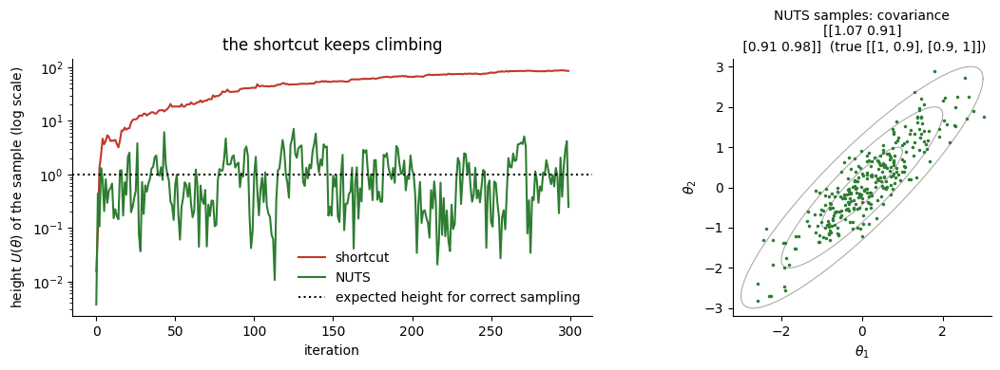

In [ ]:
#@title 🔒 hidden: experiment for section 14
T14 = Valley(0.9); res = {}
for name in ["shortcut", "NUTS"]:
    rng = np.random.default_rng(0); q = np.zeros(2); S = []
    for _ in range(EXACT_ITERS):
        q = naive_step(q, T14.U, T14.gU, 0.15, rng) if name == "shortcut" else nuts_step(q, T14.U, T14.gU, 0.15, rng)[0]
        S.append(q)
    res[name] = np.array(S)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, col in [("shortcut", RED), ("NUTS", GREEN)]:
    ax[0].plot([T14.U(q) for q in res[name]], color=col, label=name)
ax[0].axhline(1, color="k", ls=":", label="expected height for correct sampling"); ax[0].set_yscale("log")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel(r"height $U(\theta)$ of the sample (log scale)"); ax[0].legend(frameon=False)
ax[0].set_title("the shortcut keeps climbing")
T14.contours(ax[1]); S = res["NUTS"]; ax[1].plot(S[:, 0], S[:, 1], ".", color=GREEN, ms=3)
ax[1].set_title(f"NUTS samples: covariance\n{np.array2string(np.cov(S.T), precision=2)}  (true [[1, 0.9], [0.9, 1]])", fontsize=10)
plt.tight_layout(); plt.show()

**What you see.** *Left:* the red curve (shortcut) rises step after step: every proposal ends at a turning point, higher than where it started, and is accepted, so the chain walks out of the valley. The green curve (NUTS) fluctuates around the dotted line, as a correct sampler should. *Right:* the NUTS samples fill the valley and their covariance matches the truth.

## 15. Where is the randomness? A summary

| Method | Random | Deterministic | Correction |
|---|---|---|---|
| RWM | $\epsilon\sim\mathcal N(0,\sigma^2I)$; accept $u$ | – | $\tilde\pi$ ratio |
| MALA | $Z\sim\mathcal N(0,I)$; accept $u$ | drift $-\tfrac{\Delta t}{2}\nabla U$ | $\tilde\pi$ ratio × $q$ ratio |
| HMC | kick $p$; accept $u$ | $L$ leapfrog steps; proposal = end point | $e^{-\Delta H}$ |
| NUTS | kick $p$; doubling directions; which point is kept | leapfrog steps; U-turn checks | built into the choice of point |

**Common pattern:** randomness to explore, the gradient to aim, and a correction so that the chain spends time exactly in proportion to $\pi$.

## 16. Final comparison: quality per unit of computation

Two numbers per method:
- **ESS**: how many *independent* samples the chain is worth (higher = better information).
- **ESS per 1000 evaluations**: ESS divided by the computational cost, counted as evaluations of the density or its gradient (RWM: 1 per iteration; MALA: 1; HMC: $L$; NUTS: the number of leapfrog steps it chose). This answers: *which method gives the most independent information for the same amount of computing?*

In [ ]:
COMPARE_RHO, COMPARE_ITERS = 0.9, 1500
SETTINGS = dict(rwm_sigma=0.35, mala_dt=0.04, hmc_eps=0.15, hmc_L=20, nuts_eps=0.15)

method                 ESS  evaluations  ESS per 1000 eval.
RWM                     22         1500                14.7
MALA                    12         1500                 8.3
HMC (jittered L)      3046        30000               101.5
NUTS                   290        12828                22.6


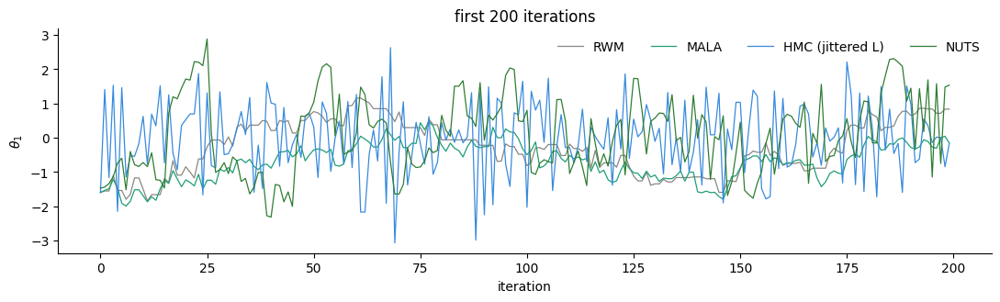

In [ ]:
#@title 🔒 hidden: comparison for section 16
Tc = Valley(COMPARE_RHO); rows = []
ch, a = rwm(Tc, COMPARE_ITERS, SETTINGS["rwm_sigma"]); rows.append(("RWM", ch[:, 0], COMPARE_ITERS))
ch, a = mala(Tc.U, Tc.gU, [-1.6, -1.4], COMPARE_ITERS, SETTINGS["mala_dt"]); rows.append(("MALA", ch[:, 0], COMPARE_ITERS))
ch, a, _ = hmc(Tc.U, Tc.gU, [-1.6, -1.4], COMPARE_ITERS, SETTINGS["hmc_eps"], SETTINGS["hmc_L"], jitter=True); rows.append(("HMC (jittered L)", ch[:, 0], COMPARE_ITERS * SETTINGS["hmc_L"]))
rng = np.random.default_rng(0); q = np.array([-1.6, -1.4]); S, ng = [], 0
for _ in range(COMPARE_ITERS):
    q, k = nuts_step(q, Tc.U, Tc.gU, SETTINGS["nuts_eps"], rng); S.append(q[0]); ng += k
rows.append(("NUTS", np.array(S), ng))
print(f"{'method':18s} {'ESS':>7s} {'evaluations':>12s} {'ESS per 1000 eval.':>19s}")
for name, x, g in rows:
    e = ess(x); print(f"{name:18s} {e:7.0f} {g:12d} {1000 * e / g:19.1f}")
fig, ax = plt.subplots(figsize=(11, 3.4))
for (name, x, g), c in zip(rows, [GRAY, TEAL, BLUE, GREEN]): ax.plot(x[:200], color=c, lw=0.9, label=name)
ax.legend(frameon=False, ncol=4); ax.set_xlabel("iteration"); ax.set_ylabel(r"$\theta_1$"); ax.set_title("first 200 iterations")
plt.tight_layout(); plt.show()

**What you see.**
- *Trace plot:* RWM (grey) and MALA (teal) wander slowly; HMC (blue) and NUTS (green) jump across the whole range every iteration.
- *ESS column:* per **iteration**, HMC and NUTS are far better (often hundreds to more than a thousand effective samples, against a few tens for RWM and MALA).
- *ESS per 1000 evaluations:* per **unit of computation** the gap is smaller, because each HMC/NUTS iteration costs many gradient evaluations. In this small 2D example the gradient-based methods still come out ahead, but not by the same factor. In higher dimensions and for harder geometry the advantage of HMC/NUTS grows strongly, because RWM and MALA must shrink their steps with the dimension.
- Takeaway: compare samplers by **ESS per unit of cost**, not by ESS per iteration alone.

Practical defaults: NUTS (Stan, PyMC, NumPyro) for continuous, differentiable models; check $\hat R$, ESS, trace plots, and divergences. Strongly separated modes remain hard for all of these methods.

Interactive demos with many more targets: <https://chi-feng.github.io/mcmc-demo/>

## 17. Multimodal targets: direct sampling vs MCMC

Use the mixture of section 0.3 as a target for MCMC, pretending we could only evaluate its density and gradient. The landscape $U=-\log p$ now has several valleys separated by ridges.
$$
\nabla U(\theta)=\sum_k r_k(\theta)\,\Sigma_k^{-1}(\theta-\mu_k),\qquad r_k(\theta)=\frac{w_k\mathcal N(\theta\mid\mu_k,\Sigma_k)}{\sum_j w_j\mathcal N(\theta\mid\mu_j,\Sigma_j)}
$$
(the gradient of each component, weighted by how responsible that component is for $\theta$).

**Experiment:** NUTS and RWM, both started in component 1, compared with direct samples. Increase the separation and watch the chains get stuck. (About 10–20 s.)

In [ ]:
def mixture_U_and_grad(weights, mus, Sigmas):
    Ps = [np.linalg.inv(S) for S in Sigmas]
    def U(theta): return -mixture_logpdf(theta, weights, mus, Sigmas)[0]
    def gU(theta):
        lt = np.array([np.log(w) - 0.5 * (theta - m) @ P @ (theta - m) - 0.5 * np.log(np.linalg.det(2 * np.pi * S))
                       for w, m, S, P in zip(weights, mus, Sigmas, Ps)])
        r = np.exp(lt - lt.max()); r /= r.sum()                       # responsibilities
        return sum(rk * P @ (theta - m) for rk, m, P in zip(r, mus, Ps))
    return U, gU

MIX_ITERS = 1500

In [ ]:
#@title 🔒 hidden: experiment for section 17
def mixture_mcmc_demo(sep=2.0, n_iter=MIX_ITERS, nuts_eps=0.2, rwm_sigma=0.8, seed=0):
    W, mus, Sigmas = mixture_setup(sep); U, gU = mixture_U_and_grad(W, mus, Sigmas)
    rng = np.random.default_rng(seed); q = mus[0].copy(); S_n = []
    for _ in range(n_iter): q, _ = nuts_step(q, U, gU, nuts_eps, rng); S_n.append(q)
    S_n = np.array(S_n)
    q = mus[0].copy(); S_r = []
    for _ in range(n_iter):
        prop = q + rwm_sigma * rng.normal(size=2)
        if np.log(rng.uniform()) < U(q) - U(prop): q = prop
        S_r.append(q)
    S_r = np.array(S_r); S_d, _ = sample_mixture(W, mus, Sigmas, n_iter, rng)
    def comp(S):   # which component is most responsible for each sample
        L = np.array([[mixture_logpdf(s, [1.0], [m], [Sg])[0] + np.log(w) for w, m, Sg in zip(W, mus, Sigmas)] for s in S])
        return np.bincount(L.argmax(1), minlength=3) / len(S)
    lim = sep + 3.5; gx = np.linspace(-lim, lim, 120); GX, GY = np.meshgrid(gx, gx)
    dens = np.exp(mixture_logpdf(np.column_stack([GX.ravel(), GY.ravel()]), W, mus, Sigmas)).reshape(GX.shape)
    fig, ax = plt.subplots(1, 4, figsize=(17, 4.3), gridspec_kw={"width_ratios": [1, 1, 1, 1.4]})
    for a, S, col, name in zip(ax[:3], [S_d, S_r, S_n], [PURPLE, GRAY, GREEN], ["direct sampling", "RWM", "NUTS"]):
        a.contour(GX, GY, dens, levels=8, colors=GRAY, linewidths=0.6); a.plot(S[:, 0], S[:, 1], ".", ms=2, color=col, alpha=0.6)
        a.set_aspect("equal"); a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
        a.set_title(f"{name}\nfractions {np.round(comp(S), 2)}", fontsize=10)
    ax[3].plot(S_r[:, 0], color=GRAY, lw=0.7, label="RWM"); ax[3].plot(S_n[:, 0], color=GREEN, lw=0.7, label="NUTS")
    ax[3].set_xlabel("iteration"); ax[3].set_ylabel(r"$\theta_1$"); ax[3].legend(frameon=False); ax[3].set_title("traces: jumps between modes?")
    print("target weights:", np.round(W, 2))
    plt.tight_layout(); plt.show()
interact(mixture_mcmc_demo, sep=FloatSlider(value=2.0, min=0.5, max=5, step=0.25, continuous_update=False),
         n_iter=IntSlider(value=MIX_ITERS, min=300, max=5000, step=100, continuous_update=False),
         nuts_eps=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.05, continuous_update=False),
         rwm_sigma=FloatSlider(value=0.8, min=0.1, max=4, step=0.1, continuous_update=False),
         seed=IntSlider(value=0, min=0, max=30, continuous_update=False));

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='sep', max=5.0, min=0.5, ste…

**What you see.** The three scatter plots show direct samples, RWM and NUTS on the same mixture; the titles give the fraction of samples in each mode, to be compared with the target weights printed above.
- *Small separation* (modes overlapping): both chains move between modes and their fractions approach the weights; NUTS does so faster.
- *Large separation* (try 4–5): direct sampling still fills all three modes with the right proportions, but the chains, started in mode 1, rarely or never leave it. The traces show long flat stretches: crossing a deep low-probability ridge is very unlikely for a random walk, and a Hamiltonian trajectory needs a kick with enough energy to climb over the ridge, which almost never comes.
- Lesson: gradient-based MCMC solves the *narrow valley* problem, not the *separated modes* problem. For multimodal posteriors use several chains from dispersed starting points (and check $\hat R$), or methods such as tempering.